<a href="https://colab.research.google.com/github/AlexandraRawrrr/python_for_ds_tasks/blob/main/Copy_of_HW_16_1_%D0%9F%D1%80%D0%BE%D0%B3%D0%BD%D0%BE%D0%B7%D1%83%D0%B2%D0%B0%D0%BD%D0%BD%D1%8F_%D0%BE%D1%80%D0%B5%D0%BD%D0%B4%D0%BD%D0%BE%D1%97_%D0%BF%D0%BB%D0%B0%D1%82%D0%B8_%D0%B7%D0%B0_%D0%B6%D0%B8%D1%82%D0%BB%D0%BE.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Домашнє завдання: Прогнозування орендної плати за житло

## Мета завдання
Застосувати знання з лекції для побудови моделі лінійної регресії, що прогнозує орендну плату за житло в Індії. Ви пройдете весь цикл вирішення задачі машинного навчання: від дослідницького аналізу до оцінки якості моделі.

## Опис датасету
**House Rent Prediction Dataset** містить інформацію про 4700+ оголошень про оренду житла в Індії з такими параметрами:
- **BHK**: Кількість спалень, залів, кухонь
- **Rent**: Орендна плата (цільова змінна)
- **Size**: Площа в квадратних футах
- **Floor**: Поверх та загальна кількість поверхів
- **Area Type**: Тип розрахунку площі
- **Area Locality**: Район
- **City**: Місто
- **Furnishing Status**: Стан меблювання
- **Tenant Preferred**: Тип орендаря
- **Bathroom**: Кількість ванних кімнат
- **Point of Contact**: Контактна особа

---

## Завдання 1: Завантаження та перший огляд даних (1 бал)

**Що потрібно зробити:**
1. Завантажте дані з файлу `House_Rent_Dataset.csv`
2. Виведіть розмір датасету
3. Покажіть перші 5 рядків
4. Виведіть загальну інформацію про дані (включно з типами даних та кількістю значень)


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [45]:
import pandas as pd
import numpy as np
import plotly.express as px
import plotly.graph_objects as go

df = pd.read_csv('/content/drive/MyDrive/House_Rent_Dataset.csv')
df.head()

,Posted On,BHK,Rent,Size,Floor,Area Type,Area Locality,City,Furnishing Status,Tenant Preferred,Bathroom,Point of Contact
0,2022-05-18,2,10000,1100,Ground out of 2,Super Area,Bandel,Kolkata,Unfurnished,Bachelors/Family,2,Contact Owner
1,2022-05-13,2,20000,800,1 out of 3,Super Area,"Phool Bagan, Kankurgachi",Kolkata,Semi-Furnished,Bachelors/Family,1,Contact Owner
2,2022-05-16,2,17000,1000,1 out of 3,Super Area,Salt Lake City Sector 2,Kolkata,Semi-Furnished,Bachelors/Family,1,Contact Owner
3,2022-07-04,2,10000,800,1 out of 2,Super Area,Dumdum Park,Kolkata,Unfurnished,Bachelors/Family,1,Contact Owner
4,2022-05-09,2,7500,850,1 out of 2,Carpet Area,South Dum Dum,Kolkata,Unfurnished,Bachelors,1,Contact Owner


In [4]:
df.shape

(4746, 12)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4746 entries, 0 to 4745
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   Posted On          4746 non-null   object
 1   BHK                4746 non-null   int64 
 2   Rent               4746 non-null   int64 
 3   Size               4746 non-null   int64 
 4   Floor              4746 non-null   object
 5   Area Type          4746 non-null   object
 6   Area Locality      4746 non-null   object
 7   City               4746 non-null   object
 8   Furnishing Status  4746 non-null   object
 9   Tenant Preferred   4746 non-null   object
 10  Bathroom           4746 non-null   int64 
 11  Point of Contact   4746 non-null   object
dtypes: int64(4), object(8)
memory usage: 445.1+ KB


## Завдання 2: Дослідницький аналіз даних (EDA) (5 балів)

**Що потрібно зробити:**
1. **Аналіз пропущених значень.** Перевірте наявність і відсоток пропущених значень у кожній колонці
2. **Базова статистика.** Обчисліть базову статистику (середнє, квартилі, стандартне відхилення) для числових змінних.
3. **Аналіз цільової змінної.** Побудуйте гістограму розподілу цільової змінної (Rent)
4. **Робота з викидами.** Знайдіть та видаліть викиди в цільовій змінній (якщо є). Визначити викиди можна будь-яким зрозумілим для вас способом, як варіант - таким, що використовується в побудові box-plot (https://en.wikipedia.org/wiki/Box_plot#Example_with_outliers).
5. **Аналіз категоріальних змінних.** Виведіть кількість унікальних значень для кожної з категоріальних колонок.


In [6]:

missing_values = df.isnull().sum()
missing_percent = (df.isnull().sum() / len(df)) * 100
missing_df = pd.DataFrame({
    'Missing Values': missing_values,
    'Percentage (%)': missing_percent
})

missing_df

,Missing Values,Percentage (%)
Posted On,0,0.0
BHK,0,0.0
Rent,0,0.0
Size,0,0.0
Floor,0,0.0
Area Type,0,0.0
Area Locality,0,0.0
City,0,0.0
Furnishing Status,0,0.0
Tenant Preferred,0,0.0


In [7]:
df.describe()

,BHK,Rent,Size,Bathroom
count,4746.000000,4.746000e+03,4746.000000,4746.000000
mean,2.083860,3.499345e+04,967.490729,1.965866
std,0.832256,7.810641e+04,634.202328,0.884532
min,1.000000,1.200000e+03,10.000000,1.000000
25%,2.000000,1.000000e+04,550.000000,1.000000
50%,2.000000,1.600000e+04,850.000000,2.000000
75%,3.000000,3.300000e+04,1200.000000,2.000000
max,6.000000,3.500000e+06,8000.000000,10.000000


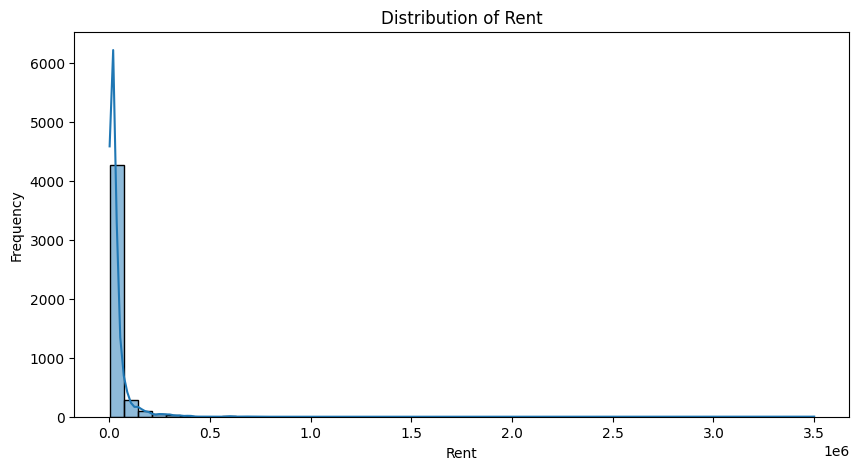

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.histplot(df['Rent'], bins=50, kde=True)

plt.title('Distribution of Rent')
plt.xlabel('Rent')
plt.ylabel('Frequency')

plt.show()

In [9]:
Q1 = df['Rent'].quantile(0.25)
Q3 = df['Rent'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[(df['Rent'] < lower_bound) | (df['Rent'] > upper_bound)]

print('Number of outliers:', len(outliers))
print('Lower bound:', lower_bound)
print('Upper bound:', upper_bound)

Number of outliers: 520
Lower bound: -24500.0
Upper bound: 67500.0


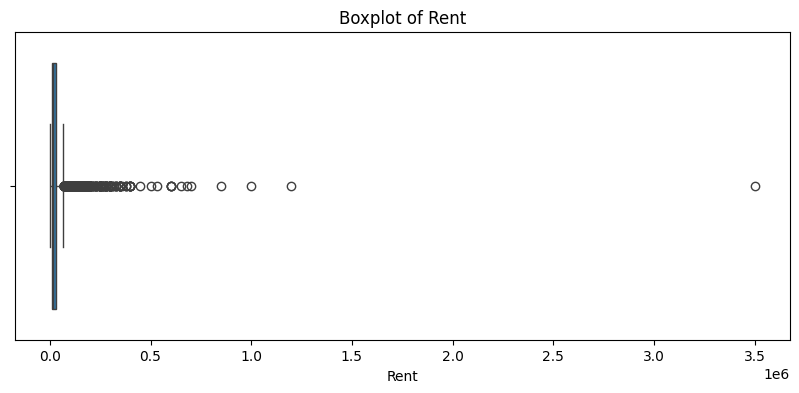

In [10]:
plt.figure(figsize=(10, 4))

sns.boxplot(x=df['Rent'])

plt.title('Boxplot of Rent')
plt.xlabel('Rent')

plt.show()

In [11]:
Q1 = df['Rent'].quantile(0.25)
Q3 = df['Rent'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[
    (df['Rent'] < lower_bound) |
    (df['Rent'] > upper_bound)
]

print('Q1:', Q1)
print('Q3:', Q3)
print('IQR:', IQR)
print('Lower bound:', lower_bound)
print('Upper bound:', upper_bound)
print('Number of outliers:', len(outliers))

Q1: 10000.0
Q3: 33000.0
IQR: 23000.0
Lower bound: -24500.0
Upper bound: 67500.0
Number of outliers: 520


In [12]:
df_clean = df[
    (df['Rent'] >= lower_bound) &
    (df['Rent'] <= upper_bound)
].copy()

print('Original dataset:', df.shape)
print('Clean dataset:', df_clean.shape)
print('Removed outliers:', len(df) - len(df_clean))

Original dataset: (4746, 12)
Clean dataset: (4226, 12)
Removed outliers: 520


In [13]:
categorical_columns = df_clean.select_dtypes(include=['object']).columns

for column in categorical_columns:
    print(f'{column}: {df_clean[column].nunique()} unique values')

Posted On: 80 unique values
Floor: 340 unique values
Area Type: 3 unique values
Area Locality: 1997 unique values
City: 6 unique values
Furnishing Status: 3 unique values
Tenant Preferred: 3 unique values
Point of Contact: 3 unique values



## Завдання 3: Аналіз кореляцій та взаємозв'язків (3 бали)

**Що потрібно зробити:**
1. Обчисліть матрицю кореляцій для числових змінних
2. Візуалізуйте кореляційну матрицю за допомогою heatmap
3. Побудуйте scatter plot між Size та Rent
4. Проаналізуйте взаємозв'язок між BHK та Rent за допомогою boxplot (який розподіл плати для різних значень BHK)


In [14]:
numeric_columns = df_clean.select_dtypes(include=['number'])

correlation_matrix = numeric_columns.corr()

correlation_matrix

,BHK,Rent,Size,Bathroom
BHK,1.000000,0.401268,0.698453,0.747918
Rent,0.401268,1.000000,0.393605,0.506528
Size,0.698453,0.393605,1.000000,0.680607
Bathroom,0.747918,0.506528,0.680607,1.000000


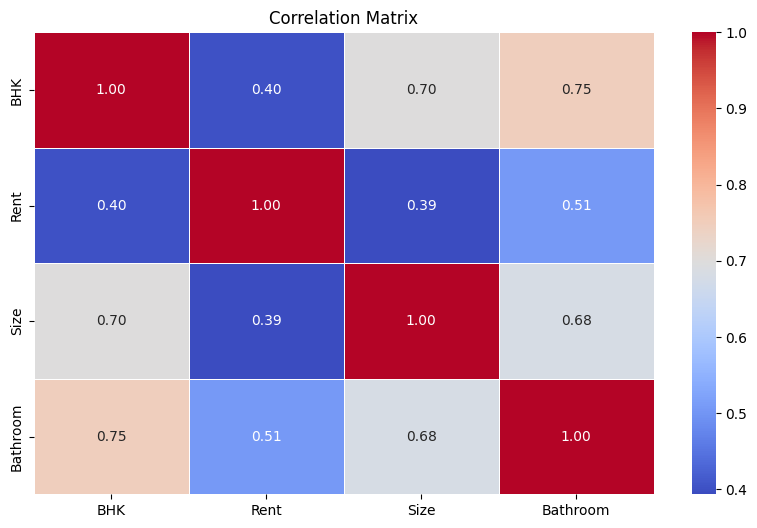

In [15]:
plt.figure(figsize=(10, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Matrix')
plt.show()

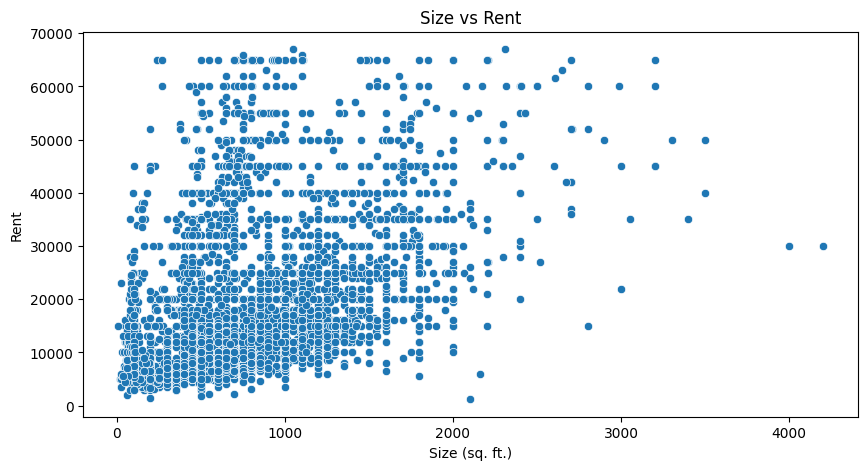

In [16]:
plt.figure(figsize=(10, 5))

sns.scatterplot(
    data=df_clean,
    x='Size',
    y='Rent'
)

plt.title('Size vs Rent')
plt.xlabel('Size (sq. ft.)')
plt.ylabel('Rent')

plt.show()

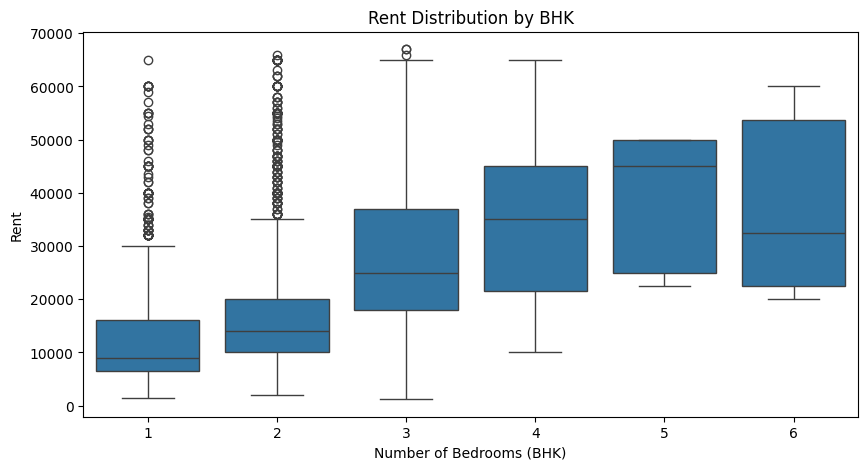

In [17]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df_clean,
    x='BHK',
    y='Rent'
)

plt.title('Rent Distribution by BHK')
plt.xlabel('Number of Bedrooms (BHK)')
plt.ylabel('Rent')

plt.show()

## Завдання 4: Feature Engineering та підготовка даних (4 бали)

**Що потрібно зробити:**
1. Закодуйте категоріальні змінні за допомогою One-Hot Encoding. Пригадайте, що в лекції ми говорили щодо кодування кат. змінних з великої кількістю різних значень і як працювати з такими випадками. Ви можете закодувати не всі кат. змінні, а лише ті, що вважаєте за потрібні (скажімо ті, що мають відносно небагато різних значень).
2. **Опціонально (по 0.5 бала за кожну доцільну ознаку):** Додайте нові ознаки, обчислені на основі наявних даних, які б на ваш погляд були корисними для моделі
3. Виберіть ознаки для побудови моделі (виключіть непотрібні колонки). Виключити можна, наприклад, ті колонки, які мають категоріальний тип і забагато (більше 20) різних значень. Треба виключити хоча б 1 колонку.
4. Розділіть дані на ознаки (X) та цільову змінну (y)
5. Застосуйте стандартизацію до числових ознак


In [29]:
#Кодуємо категоріальні змінні

dummies = pd.get_dummies(
    df_clean[['Area Type', 'City', 'Furnishing Status', 'Tenant Preferred', 'Point of Contact']]
)

df_clean = pd.concat([df_clean, dummies], axis=1)

In [30]:
# Витягуємо поверхи з колонки "Floor" та створюємо дві нові колонки

df_floors = df_clean['Floor'].str.split(' out of ', expand=True)
df_floors = df_floors.rename(columns={
    0: 'appart_floor',
    1: 'total_floors'
})
df_floors = df_floors.replace('Ground', '0')
df_floors[df_floors.isna().any(axis=1)]

,appart_floor,total_floors
2553,3,None
2883,0,None
4490,1,None
4560,1,None


In [31]:
df_clean = pd.concat([df_clean, df_floors], axis=1)

In [32]:
df_clean = df_clean.dropna()

In [33]:
df_clean.loc[
    ~df_clean['appart_floor'].astype(str).str.fullmatch(r'\d+'),
    'appart_floor'
].value_counts()

,count
appart_floor,
Upper Basement,18
Lower Basement,10


In [34]:
df_clean = df_clean[~df_clean['appart_floor'].isin(['Upper Basement', 'Lower Basement'])]
df_clean[['appart_floor', 'total_floors']] = df_clean[['appart_floor', 'total_floors']].astype(int)

In [35]:
# Витягуємо місяць публікації оголошень

df_clean['Posted On'] = pd.to_datetime(df_clean['Posted On'])
df_clean['posted_month'] = df_clean['Posted On'].dt.month
df_clean['posted_month'].value_counts().sort_values()

,count
posted_month,
4,220
7,797
5,1548
6,1629


In [47]:
fig = px.box(
    df_clean,
    x='posted_month',
    y='Rent',
    width=500,
    height=400,
    points='outliers'
)

fig.show()

In [48]:
df_clean.columns

Index(['Posted On', 'BHK', 'Rent', 'Size', 'Floor', 'Area Type',
       'Area Locality', 'City', 'Furnishing Status', 'Tenant Preferred',
       'Bathroom', 'Point of Contact', 'Area Type_Built Area',
       'Area Type_Carpet Area', 'Area Type_Super Area', 'City_Bangalore',
       'City_Chennai', 'City_Delhi', 'City_Hyderabad', 'City_Kolkata',
       'City_Mumbai', 'Furnishing Status_Furnished',
       'Furnishing Status_Semi-Furnished', 'Furnishing Status_Unfurnished',
       'Tenant Preferred_Bachelors', 'Tenant Preferred_Bachelors/Family',
       'Tenant Preferred_Family', 'Point of Contact_Contact Agent',
       'Point of Contact_Contact Builder', 'Point of Contact_Contact Owner',
       'appart_floor', 'total_floors', 'posted_month', 'appart_floor',
       'total_floors', 'appart_floor', 'total_floors', 'appart_floor',
       'total_floors', 'appart_floor', 'total_floors', 'appart_floor',
       'total_floors'],
      dtype='object')

In [49]:
metrics_df_clean = df_clean.select_dtypes(include='number')
correlation_matrix_clean = metrics_df_clean.corr()

fig = px.imshow(
    correlation_matrix_clean,
    text_auto='.2f',
    color_continuous_scale='RdBu_r',
    title='Кореляція між числовими змінними',
    labels=dict(color="Кореляція")
)
fig.update_layout(height=500)
fig.show()

Найсильніший позитивний зв’язок з орендною платою (Rent) має кількість поверхів у будівлі (total_floors) — 0,53, а також кількість ванних кімнат (Bathroom) — 0,51. Кількість спалень (BHK) та площа житла (Size) мають помірну позитивну кореляцію — по 0,40. Це свідчить про те, що збільшення цих характеристик загалом пов’язане зі зростанням орендної плати. Найсильніша кореляція між незалежними змінними спостерігається між appart_floor та total_floors — 0,81.

In [50]:
metrics_df_clean = metrics_df_clean.drop(columns='Rent')

In [51]:
features = metrics_df_clean.columns.tolist() + dummies.columns.tolist()
features

['BHK',
 'Size',
 'Bathroom',
 'appart_floor',
 'total_floors',
 'posted_month',
 'appart_floor',
 'total_floors',
 'appart_floor',
 'total_floors',
 'appart_floor',
 'total_floors',
 'appart_floor',
 'total_floors',
 'appart_floor',
 'total_floors',
 'Area Type_Built Area',
 'Area Type_Carpet Area',
 'Area Type_Super Area',
 'City_Bangalore',
 'City_Chennai',
 'City_Delhi',
 'City_Hyderabad',
 'City_Kolkata',
 'City_Mumbai',
 'Furnishing Status_Furnished',
 'Furnishing Status_Semi-Furnished',
 'Furnishing Status_Unfurnished',
 'Tenant Preferred_Bachelors',
 'Tenant Preferred_Bachelors/Family',
 'Tenant Preferred_Family',
 'Point of Contact_Contact Agent',
 'Point of Contact_Contact Builder',
 'Point of Contact_Contact Owner']

In [52]:
X = df_clean[features]
y = df_clean['Rent']

print(f"\nРозмір X (ознак): {X.shape}")
print(f"Розмір y (цілі): {y.shape}")


Розмір X (ознак): (4226, 94)
Розмір y (цілі): (4226,)


In [55]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_scaled_df = pd.DataFrame(X_scaled, columns=X.columns, index=X.index)

## Завдання 5: Розділення даних та навчання моделі (3 бали)

**Що потрібно зробити:**
1. Розділіть дані на навчальну (80%) та тестову (20%) вибірки.
2. Створіть модель лінійної регресії.
3. Навчіть модель на навчальних даних.
4. Виведіть усі коефіцієнти моделі (ваги) та напишіть, які 2 ознаки найбільше впливають на прогноз.
5. Зробіть прогнози на тренувальній та тестовій вибірках.

In [56]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train, y_train)

print('Model training completed!')

Model training completed!


In [57]:
coefficients = pd.DataFrame({
    'Feature': X_train.columns,
    'Coefficient': model.coef_
})

coefficients['Abs_Coefficient'] = coefficients['Coefficient'].abs()

coefficients = coefficients.sort_values(
    by='Abs_Coefficient',
    ascending=False
)

coefficients

,Feature,Coefficient,Abs_Coefficient
10,City_Mumbai,18541.333492,18541.333492
16,Point of Contact_Contact Owner,-8778.869259,8778.869259
15,Point of Contact_Contact Builder,-5837.606156,5837.606156
12,Furnishing Status_Unfurnished,-4546.456082,4546.456082
1,Size,3835.933427,3835.933427
11,Furnishing Status_Semi-Furnished,-3410.942912,3410.942912
9,City_Kolkata,-3260.113772,3260.113772
5,Area Type_Super Area,-2641.382145,2641.382145
0,BHK,2618.793984,2618.793984
4,Area Type_Carpet Area,-2394.307753,2394.307753


In [58]:
print('Top 2 most influential features:')

coefficients.head(2)

Top 2 most influential features:


,Feature,Coefficient,Abs_Coefficient
10,City_Mumbai,18541.333492,18541.333492
16,Point of Contact_Contact Owner,-8778.869259,8778.869259


In [59]:
y_train_pred = model.predict(X_train)

y_test_pred = model.predict(X_test)

print('Train predictions:', len(y_train_pred))
print('Test predictions:', len(y_test_pred))

Train predictions: 3380
Test predictions: 846


In [60]:
comparison = pd.DataFrame({
    'Actual Rent': y_test.values,
    'Predicted Rent': y_test_pred
})

comparison.head(10).round(2)

,Actual Rent,Predicted Rent
0,22000,28112.45
1,5000,3380.18
2,37000,40390.93
3,8000,2958.68
4,15000,15364.56
5,20000,24012.07
6,8500,17779.37
7,7000,4016.72
8,3000,81.62
9,8000,5780.24


In [62]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Train metrics
train_mae = mean_absolute_error(y_train, y_train_pred)
train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred))
train_r2 = r2_score(y_train, y_train_pred)

# Test metrics
test_mae = mean_absolute_error(y_test, y_test_pred)
test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))
test_r2 = r2_score(y_test, y_test_pred)

print('TRAIN RESULTS')
print('MAE:', round(train_mae, 2))
print('RMSE:', round(train_rmse, 2))
print('R2:', round(train_r2, 4))

print('\nTEST RESULTS')
print('MAE:', round(test_mae, 2))
print('RMSE:', round(test_rmse, 2))
print('R2:', round(test_r2, 4))

TRAIN RESULTS
MAE: 5540.62
RMSE: 7698.8
R2: 0.6895

TEST RESULTS
MAE: 5537.34
RMSE: 7737.62
R2: 0.6878


## Завдання 6: Оцінка якості моделі (2 бали)

**Що потрібно зробити:**
1. Обчисліть MAE, RMSE та R² для навчальної та тестової вибірок
2. Порівняйте метрики та зробіть висновок про якість моделі
3. Проаналізуйте і дайте висновок, чи є ознаки перенавчання або недонавчання (**Нагадування**: перенавчання - коли модель дуже добре працює на тренувальних даних, але погано на тестових; недонавчання - коли модель погано працює навіть на тренувальних даних)
4. Побудуйте графік розсіювання "реальні vs прогнозовані значення" та зробіть висновок про якість моделі


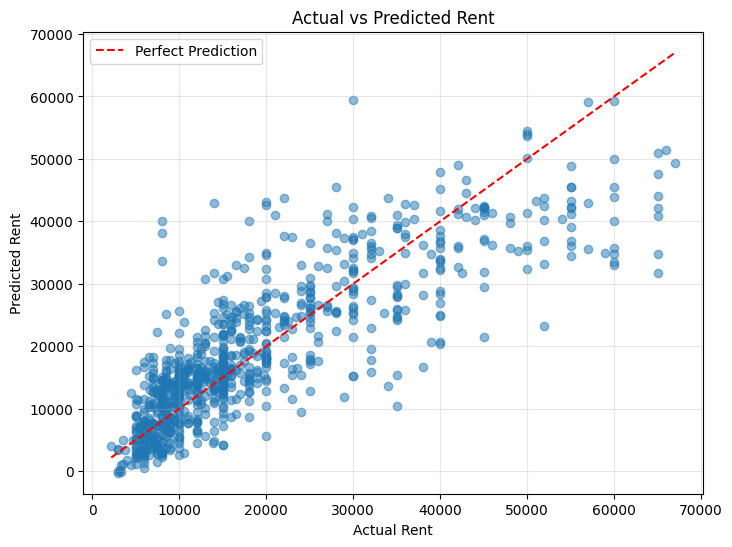

In [63]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_test_pred,
    alpha=0.5
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--',
    label='Perfect Prediction'
)

plt.title('Actual vs Predicted Rent')
plt.xlabel('Actual Rent')
plt.ylabel('Predicted Rent')
plt.legend()
plt.grid(alpha=0.3)

plt.show()

### Висновок щодо якості моделі

За результатами оцінювання моделі Linear Regression отримано такі показники на тестовій вибірці: MAE = 5537.34, RMSE = 7737.62, R² = 0.6878.

Порівняння метрик навчальної та тестової вибірок показало дуже близькі результати. Це свідчить про стабільну роботу моделі та відсутність суттєвих ознак перенавчання.

Модель пояснює приблизно 68.78% варіації орендної плати. Водночас значення MAE та RMSE вказують на наявність помилок прогнозування.

Отже, модель демонструє помірну якість прогнозування, але може бути вдосконалена шляхом подальшого відбору ознак та оптимізації моделі.

## Завдання 7: Аналіз помилок (4 бали)

**Що потрібно зробити:**
1. Обчисліть помилки (residuals = реальні - прогнозовані значення)
2. Побудуйте гістограму розподілу помилок
3. Створіть scatter plot помилок відносно величини прогнозованих значень. Чи росте помилка з ростом прогнозованого значення?
4. Знайдіть 5 прогнозів з найбільшими помилками
5. Проаналізуйте, на яких типах житла модель помиляється найбільше. Типи можна розрізняти за кількістю кімнат чи містом, наприклад.
6. Подумайте і напишіть, які наступні кроки ви б зробили, аби поліпшити якість моделі. Опціонально можна їх зробити і ми перевіримо :)

In [64]:
error_analysis = pd.DataFrame({
    'Actual_Rent': y_test.values,
    'Predicted_Rent': y_test_pred
}, index=y_test.index)


error_analysis['Residual'] = (
    error_analysis['Actual_Rent'] -
    error_analysis['Predicted_Rent']
)


error_analysis['Abs_Error'] = error_analysis['Residual'].abs()

error_analysis.head(10).round(2)

,Actual_Rent,Predicted_Rent,Residual,Abs_Error
1998,22000,28112.45,-6112.45,6112.45
3190,5000,3380.18,1619.82,1619.82
2670,37000,40390.93,-3390.93,3390.93
4647,8000,2958.68,5041.32,5041.32
4488,15000,15364.56,-364.56,364.56
2672,20000,24012.07,-4012.07,4012.07
2802,8500,17779.37,-9279.37,9279.37
352,7000,4016.72,2983.28,2983.28
221,3000,81.62,2918.38,2918.38
491,8000,5780.24,2219.76,2219.76


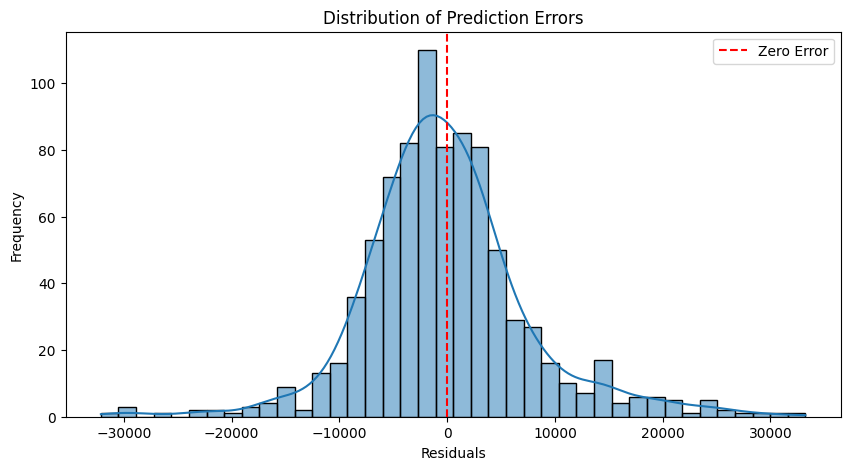

In [65]:
plt.figure(figsize=(10, 5))

sns.histplot(
    error_analysis['Residual'],
    bins=40,
    kde=True
)

plt.axvline(
    0,
    color='red',
    linestyle='--',
    label='Zero Error'
)

plt.title('Distribution of Prediction Errors')
plt.xlabel('Residuals')
plt.ylabel('Frequency')
plt.legend()

plt.show()

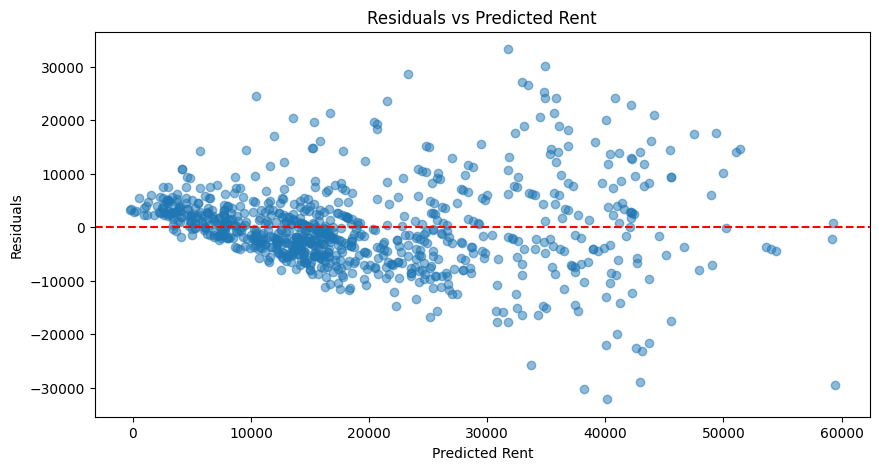

In [66]:
plt.figure(figsize=(10, 5))

plt.scatter(
    error_analysis['Predicted_Rent'],
    error_analysis['Residual'],
    alpha=0.5
)

plt.axhline(
    0,
    color='red',
    linestyle='--'
)

plt.title('Residuals vs Predicted Rent')
plt.xlabel('Predicted Rent')
plt.ylabel('Residuals')

plt.show()

In [67]:

error_analysis['City'] = df_clean.loc[
    error_analysis.index, 'City'
]

error_analysis['BHK'] = df_clean.loc[
    error_analysis.index, 'BHK'
]

error_analysis['Bathroom'] = df_clean.loc[
    error_analysis.index, 'Bathroom'
]


worst_predictions = error_analysis.sort_values(
    by='Abs_Error',
    ascending=False
).head(5)

worst_predictions.round(2)

,Actual_Rent,Predicted_Rent,Residual,Abs_Error,City,BHK,Bathroom
3962,65000,31749.85,33250.15,33250.15,Hyderabad,3.0,3.0
549,8000,40132.36,-32132.36,32132.36,NaN,NaN,NaN
904,8000,38198.62,-30198.62,30198.62,Mumbai,2.0,2.0
3520,65000,34853.52,30146.48,30146.48,Chennai,3.0,3.0
275,30000,59404.34,-29404.34,29404.34,Kolkata,4.0,3.0


In [69]:
error_analysis = pd.DataFrame({
    'Actual_Rent': y_test.to_numpy(),
    'Predicted_Rent': y_test_pred
}, index=y_test.index)

error_analysis['Residual'] = (
    error_analysis['Actual_Rent'] -
    error_analysis['Predicted_Rent']
)

error_analysis['Abs_Error'] = error_analysis['Residual'].abs()

error_analysis = error_analysis.join(
    df_model[['City', 'BHK', 'Bathroom']],
    how='left'
)

worst_predictions = error_analysis.nlargest(
    5, 'Abs_Error'
)

worst_predictions.round(2)

,Actual_Rent,Predicted_Rent,Residual,Abs_Error,City,BHK,Bathroom
3962,65000,31749.85,33250.15,33250.15,Hyderabad,3,3
549,8000,40132.36,-32132.36,32132.36,Mumbai,2,2
904,8000,38198.62,-30198.62,30198.62,Mumbai,2,2
3520,65000,34853.52,30146.48,30146.48,Chennai,3,3
275,30000,59404.34,-29404.34,29404.34,Kolkata,4,3


In [70]:
city_errors = error_analysis.groupby('City').agg(
    Properties=('Abs_Error', 'count'),
    Mean_Absolute_Error=('Abs_Error', 'mean'),
    Average_Error=('Residual', 'mean')
).sort_values(
    by='Mean_Absolute_Error',
    ascending=False
)

city_errors.round(2)

,Properties,Mean_Absolute_Error,Average_Error
City,,,
Mumbai,118,9182.44,-1025.07
Delhi,115,7321.43,1602.09
Hyderabad,165,5070.90,117.50
Chennai,143,4731.84,162.75
Kolkata,131,4208.82,-1413.30
Bangalore,174,3990.74,-301.40


In [71]:
bhk_errors = error_analysis.groupby('BHK').agg(
    Properties=('Abs_Error', 'count'),
    Mean_Absolute_Error=('Abs_Error', 'mean'),
    Average_Error=('Residual', 'mean')
).sort_values(
    by='Mean_Absolute_Error',
    ascending=False
)

bhk_errors.round(2)

,Properties,Mean_Absolute_Error,Average_Error
BHK,,,
4,17,12019.81,-3871.38
3,152,7886.11,1289.04
6,2,5419.69,5419.69
2,450,5034.49,-967.77
1,224,4467.72,747.00
5,1,4433.69,-4433.69


### Аналіз помилок моделі залежно від міста та кількості спалень

Результати аналізу показали, що точність прогнозування моделі відрізняється залежно від міста та характеристик житла.

Серед міст найбільша середня абсолютна помилка спостерігається в Мумбаї (9182.44), а найменша — у Бангалорі (3990.74).

За кількістю спалень найбільша середня абсолютна помилка зафіксована для житла з чотирма спальнями (12019.81), а також із трьома спальнями (7886.11). Для об'єктів з однією та двома спальнями помилки прогнозування є меншими.

Водночас результати для житла з п'ятьма та шістьма спальнями не є достатньо репрезентативними через малу кількість спостережень у цих категоріях.

**Висновок:** модель менш точно прогнозує орендну плату для об'єктів у Мумбаї та для житла з більшою кількістю спалень. Це може бути пов'язано з більшою різноманітністю цін у цих категоріях та недостатньою кількістю однорідних прикладів для навчання.

### Подальші кроки для покращення моделі

Для покращення якості прогнозування можна виконати такі кроки:

1. Спробувати логарифмічне перетворення цільової змінної Rent для зменшення впливу екстремальних значень.
2. Провести додатковий аналіз викидів та оцінити їхній вплив на результати моделі.
3. Додати більш детальну інформацію про місце розташування житла, зокрема Area Locality.
4. Спробувати нелінійні алгоритми машинного навчання, наприклад Random Forest або Gradient Boosting.
5. Використати крос-валідацію для більш надійної оцінки якості моделі.

Ці кроки можуть допомогти зменшити похибки прогнозування та покращити точність моделі.